# Triangle plots for subluminal chains, constant $c_s^2$, with CMB lensing and DES, without the quasi-static approximation

In [1]:
import numpy as np
import getdist
from getdist import plots
from matplotlib.lines import Line2D

import utils

In [2]:
indices = [76, 84, 98, 99, 100, 101, 117, 118, 119, 120]
chains = {}
for i in indices:
    chains[i] = utils.load_chain(i, burn_in=0.6, smooth_2D=0.35, smooth_1D=0.35)

../chains/MCMC76/MCMC76.1.txt


../chains/MCMC76/MCMC76.2.txt


../chains/MCMC76/MCMC76.3.txt


../chains/MCMC76/MCMC76.4.txt


Removed no burn in


...

../chains/MCMC84/MCMC84.4.txt


Removed no burn in


../chains/MCMC100/MCMC100.1.txt
../chains/MCMC100/MCMC100.2.txt
../chains/MCMC100/MCMC100.3.txt
../chains/MCMC100/MCMC100.4.txt


Removed no burn in
../chains/MCMC101/MCMC101.1.txt
../chains/MCMC101/MCMC101.2.txt


../chains/MCMC101/MCMC101.3.txt
../chains/MCMC101/MCMC101.4.txt
Removed no burn in


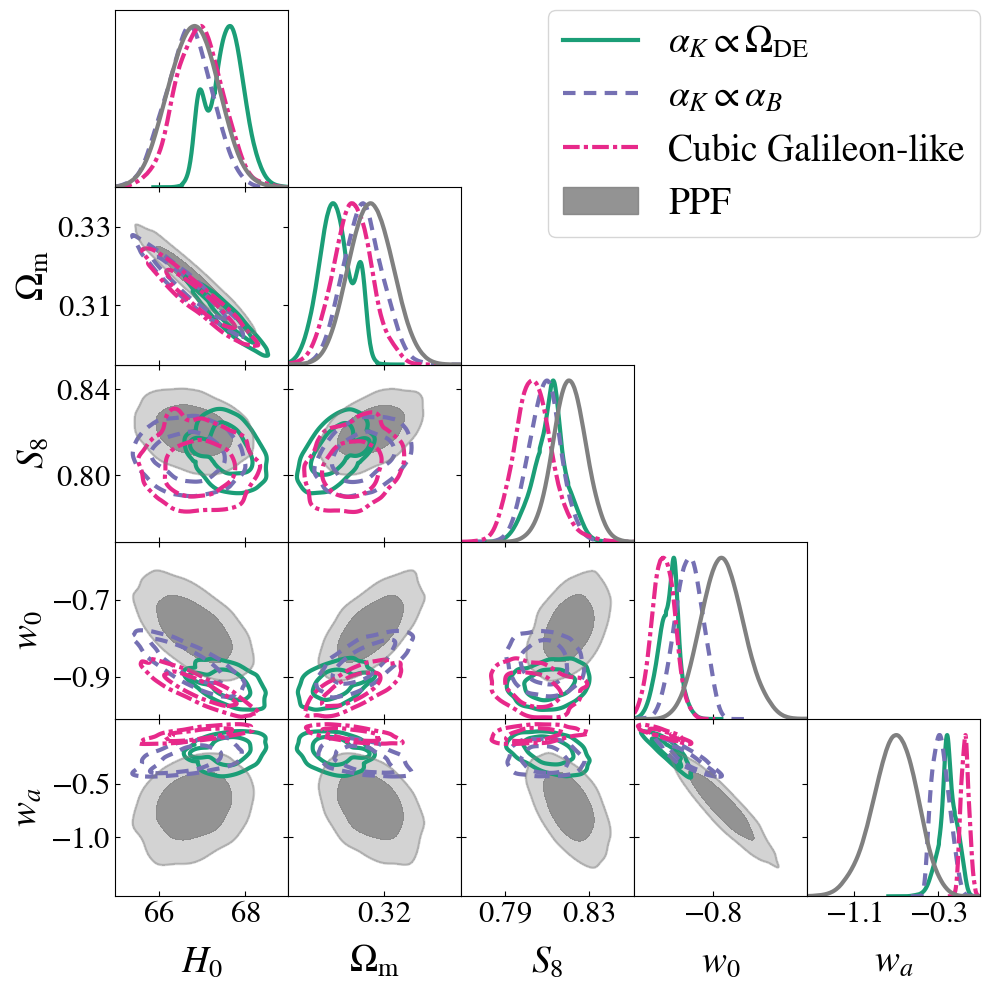

In [3]:
p = plots.get_subplot_plotter()
p.settings.axes_fontsize=25
p.settings.axes_labelsize=30
p.settings.legend_fontsize=30
p.triangle_plot(
    [chains[117], chains[119], chains[120], chains[76]],
    ["H0", "omegam", "S8", "w", "wa"],
    filled=[False, False, False, True],
    contour_colors=[utils.colors[0], utils.colors[2], utils.colors[3], "gray"],
    contour_lws=3,
    contour_ls=["-", "--", "-.", "-"],
    legend_labels=["$\\alpha_K \\propto \\Omega_\\mathrm{DE}$", "$\\alpha_K \\propto \\alpha_B$", "Cubic Galileon-like", "PPF"],
    legend_loc="upper right",
    param_limits={"w": [-1.01, -0.55], "wa": [-1.55, 0.1], "H0": [65, 69], "omegam": [0.295, 0.34]}
)
p.fig.savefig("plots/triangle_ds2_subluminal_mg_noqsa.pdf", bbox_inches="tight")

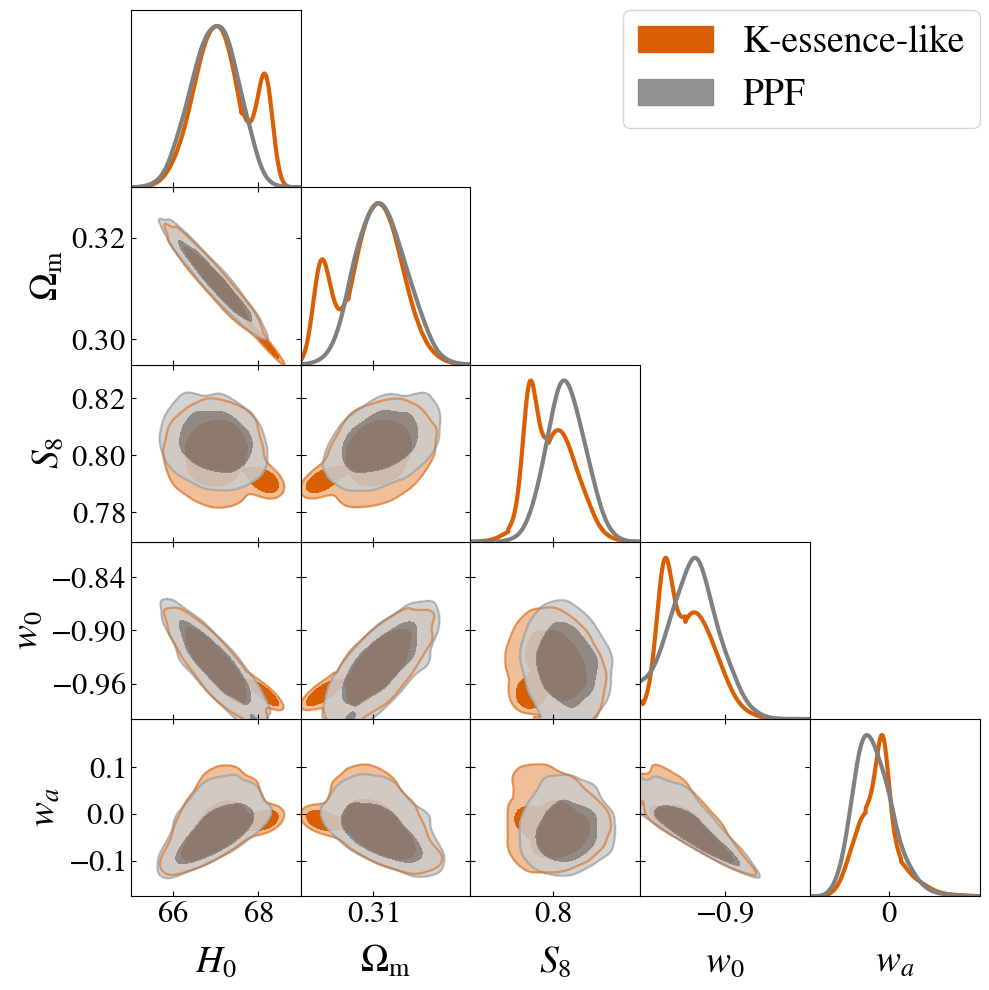

In [4]:
p = plots.get_subplot_plotter()
p.settings.axes_fontsize=25
p.settings.axes_labelsize=30
p.settings.legend_fontsize=30
p.triangle_plot(
    [chains[118], chains[84]],
    ["H0", "omegam", "S8", "w", "wa"],
    filled=[True, True],
    contour_colors=[utils.colors[1], "gray"],
    contour_lws=3,
    contour_ls='-',
    legend_labels=["K-essence-like", "PPF"],
    legend_loc="upper right",
    param_limits={"w": [-1, -0.8], "H0": [65, 69], "omegam": [0.295, 0.33]}
)
p.fig.savefig("plots/triangle_ds2_subluminal_mg_kessence_noqsa.pdf", bbox_inches="tight")

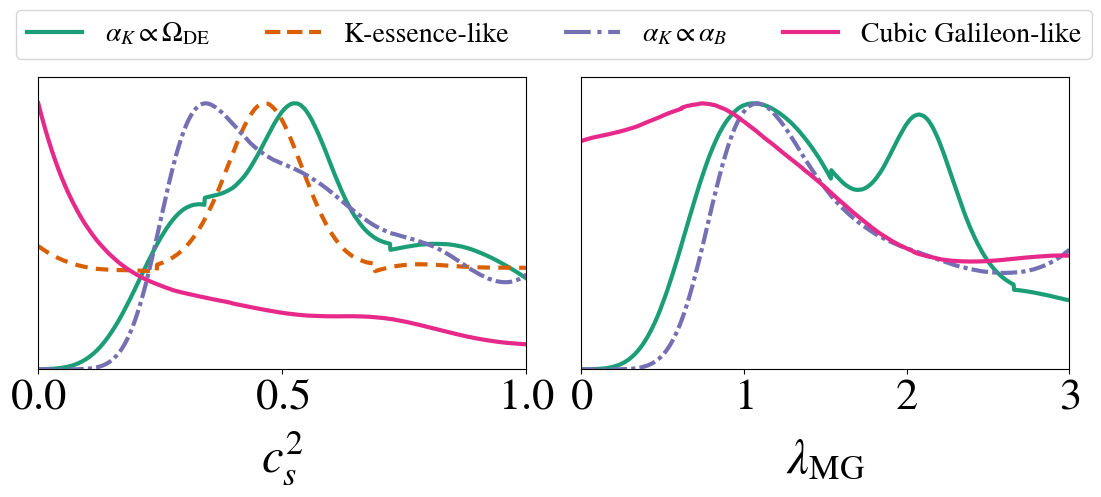

In [5]:
p = plots.get_subplot_plotter(width_inch=11, subplot_size_ratio=4/5)
p.settings.axes_fontsize=32
p.settings.axes_labelsize=35
p.settings.legend_fontsize=30
labels = ["$\\alpha_K \\propto \\Omega_\\mathrm{DE}$", "K-essence-like", "$\\alpha_K \\propto \\alpha_B$", "Cubic Galileon-like"]
p.plots_1d(
    [chains[117], chains[118], chains[119], chains[120]],
    ["cs2_0", "alpha_K_0"],
    colors=utils.colors,
    lws=3,
    ls=["-", "--", "-.", "-"],
    nx=2,
    legend_labels=[],
)

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], linewidth=3, linestyle="-",  color=utils.colors[0]),
    Line2D([], [], linewidth=3, linestyle="--", color=utils.colors[1]),
    Line2D([], [], linewidth=3, linestyle="-.", color=utils.colors[2]),
    Line2D([], [], linewidth=3, linestyle="-",  color=utils.colors[3]),
]

# place legend relative to the figure (x,y in figure coordinates)
p.fig.legend(handles, labels,
             loc="upper center",
             ncol=4,
             fontsize=20,
             bbox_to_anchor=(0.508, 1.15),
             bbox_transform=p.fig.transFigure,
             frameon=True)

p.fig.savefig("plots/lambda_mg_cs2_subluminal_ds2_noqsa.pdf", bbox_inches="tight")

In [6]:
def latex_value(chain, param):
    if not chain.paramNames.hasParam(param): return "---"
    latex = chain.getInlineLatex(param)
    return f"${latex.split('=')[1]}$" if "=" in latex else f"${latex}$"

def print_table(columns, parameters):
    params = {name.name: label for name, label in zip(chains[117].paramNames.names, chains[117].paramNames.labels())}
    for param in parameters:
        print(f"${params[param]}$ & " + " & ".join(latex_value(chains[i], param) for i in columns) + r" \\ \hline")

In [7]:
# Getting numbers (same column order as the QSA table: PPF, Omega_DE, alpha_B, Cubic Galileon, K-essence, PPF w0waq)
print_table([76, 117, 119, 120, 118, 84], ["omegam", "H0", "S8", "w", "wa", "cs2_0", "alpha_K_0"])

$\Omega_\mathrm{m}$ & $ 0.3165\pm 0.0057$ & $ 0.3077^{+0.0064}_{-0.0044}$ & $ 0.3144^{+0.0049}_{-0.0055}$ & $ 0.3117\pm 0.0051$ & $ 0.3087^{+0.0077}_{-0.010}$ & $ 0.3117^{+0.0048}_{-0.0057}$ \\ \hline
$H_0$ & $ 66.81\pm 0.57$ & $ 67.53^{+0.47}_{-0.63}$ & $ 66.70\pm 0.53$ & $ 66.93\pm 0.54$ & $ 67.24^{+0.96}_{-0.67}$ & $ 66.97\pm 0.56$ \\ \hline
$S_8$ & $ 0.8206\pm 0.0081$ & $ 0.8114\pm 0.0077$ & $ 0.8089\pm 0.0076$ & $ 0.8038^{+0.0080}_{-0.0094}$ & $ 0.7986^{+0.0067}_{-0.0099}$ & $ 0.8046\pm 0.0075$ \\ \hline
$w_0$ & $ -0.774^{+0.053}_{-0.061}$ & $ -0.917^{+0.027}_{-0.024}$ & $ -0.864\pm 0.036$ & $ -0.932\pm 0.030$ & $ -0.946^{+0.021}_{-0.035}$ & $ -0.937\pm 0.030$ \\ \hline
$w_a$ & $ -0.72^{+0.23}_{-0.19}$ & $ -0.206^{+0.094}_{-0.069}$ & $ -0.273^{+0.067}_{-0.098}$ & $ -0.043^{+0.035}_{-0.043}$ & $ -0.022^{+0.033}_{-0.047}$ & $ -0.033^{+0.036}_{-0.050}$ \\ \hline
$c_s^2$ & $ ---$ & $ 0.55^{+0.17}_{-0.31}$ & $ 0.53^{+0.15}_{-0.28}$ & $c_s^2 < 0.464$ & $c_s^2 < 0.588$ & $ ---$ \\ \hline

## Comparison with the QSA chains

QSA chains: 98-101, linear lensing; the exact QSA counterparts of 117-120 are 79-82, with nonlinear lensing. Dashed: QSA; solid: no QSA; gray: PPF.

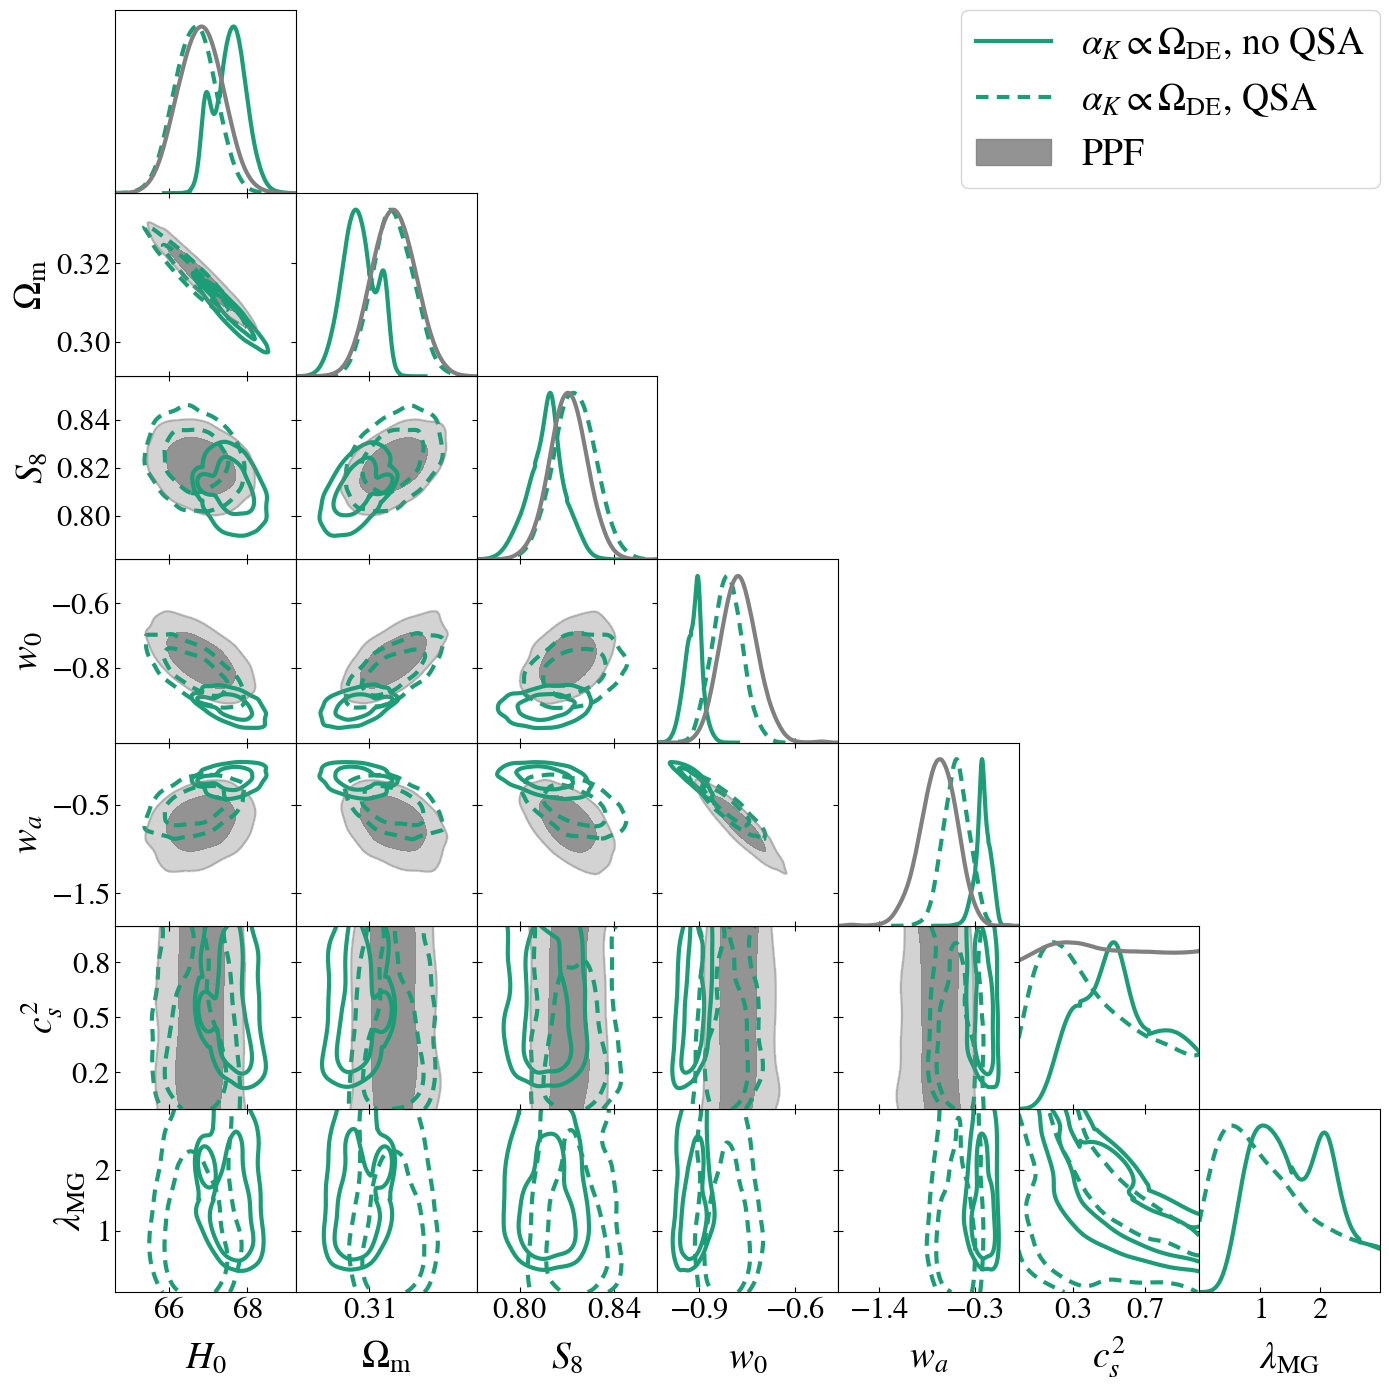

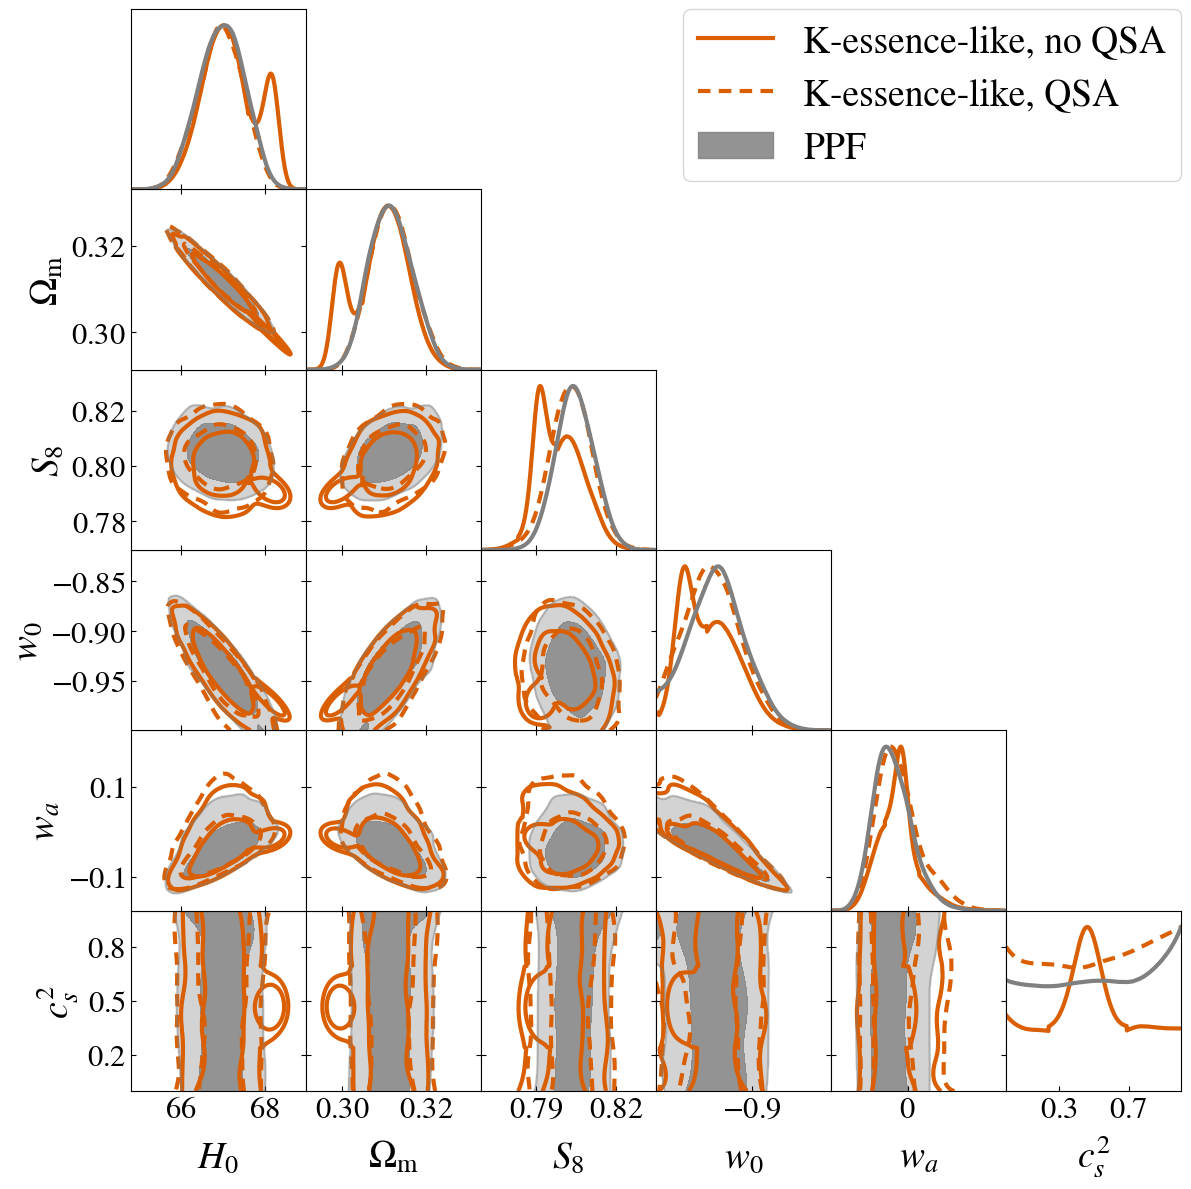

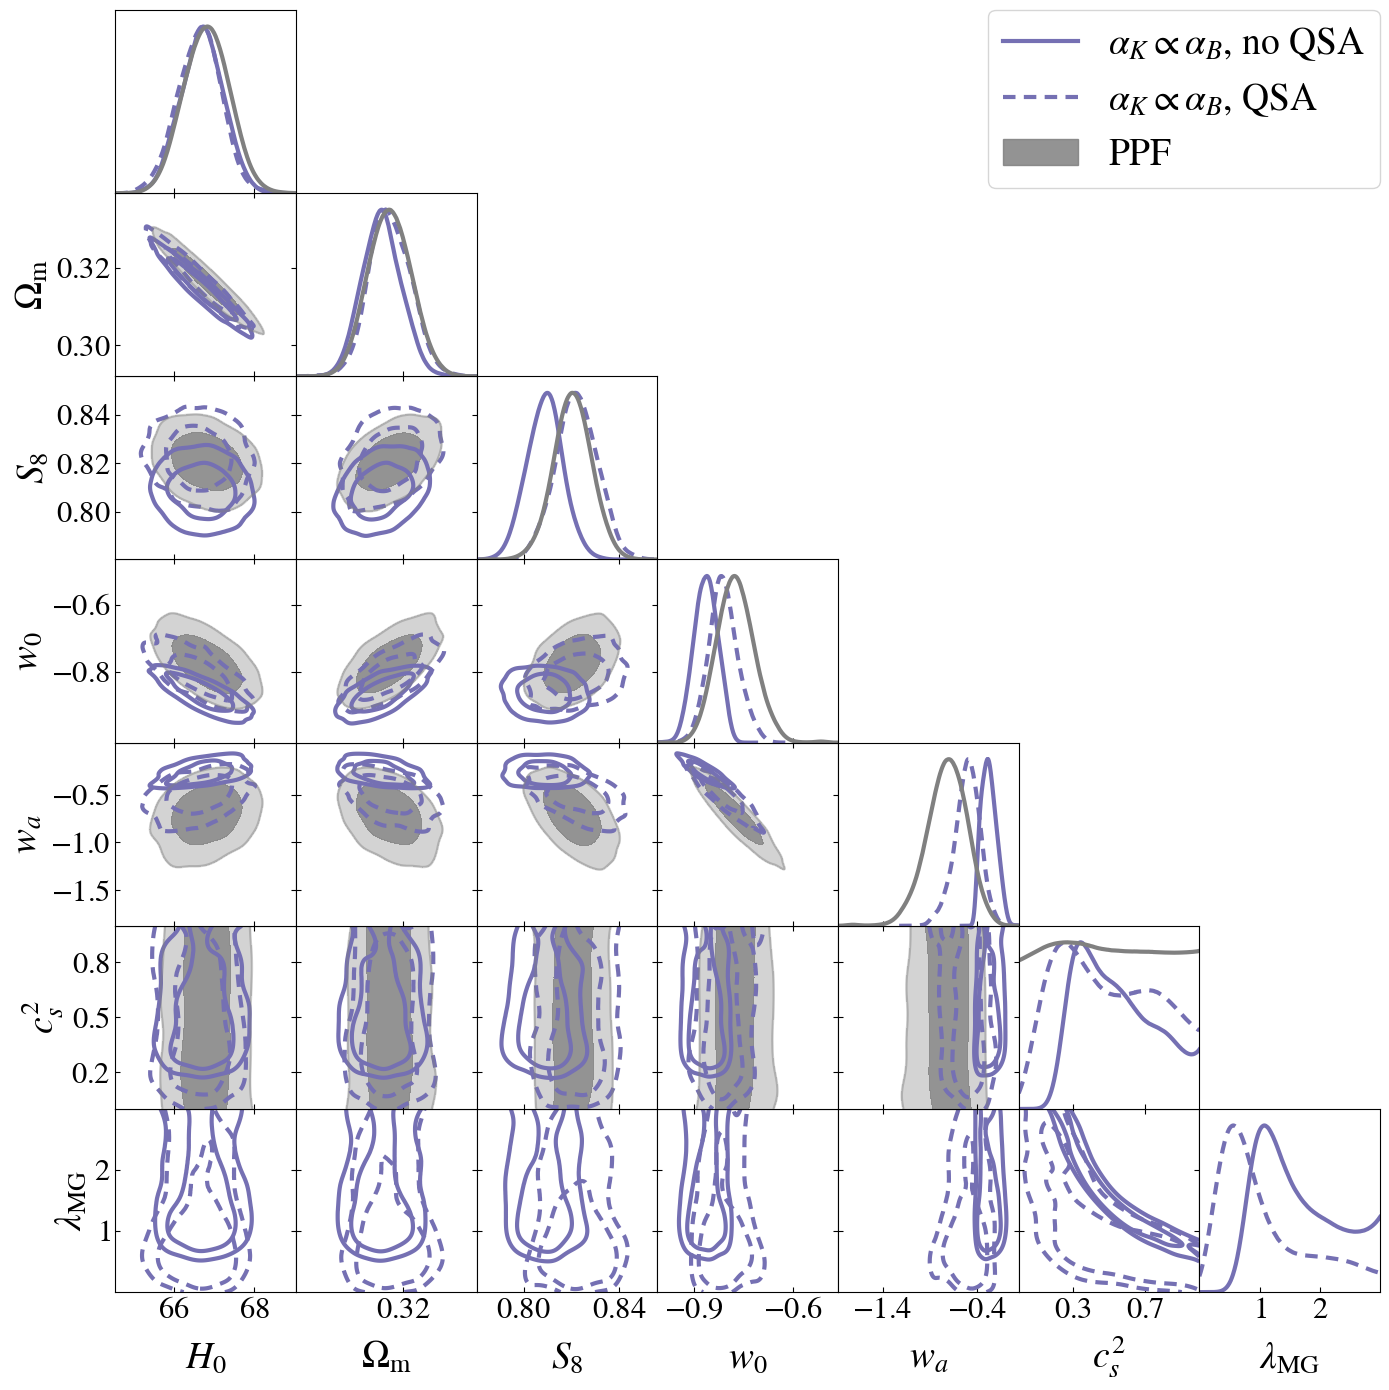

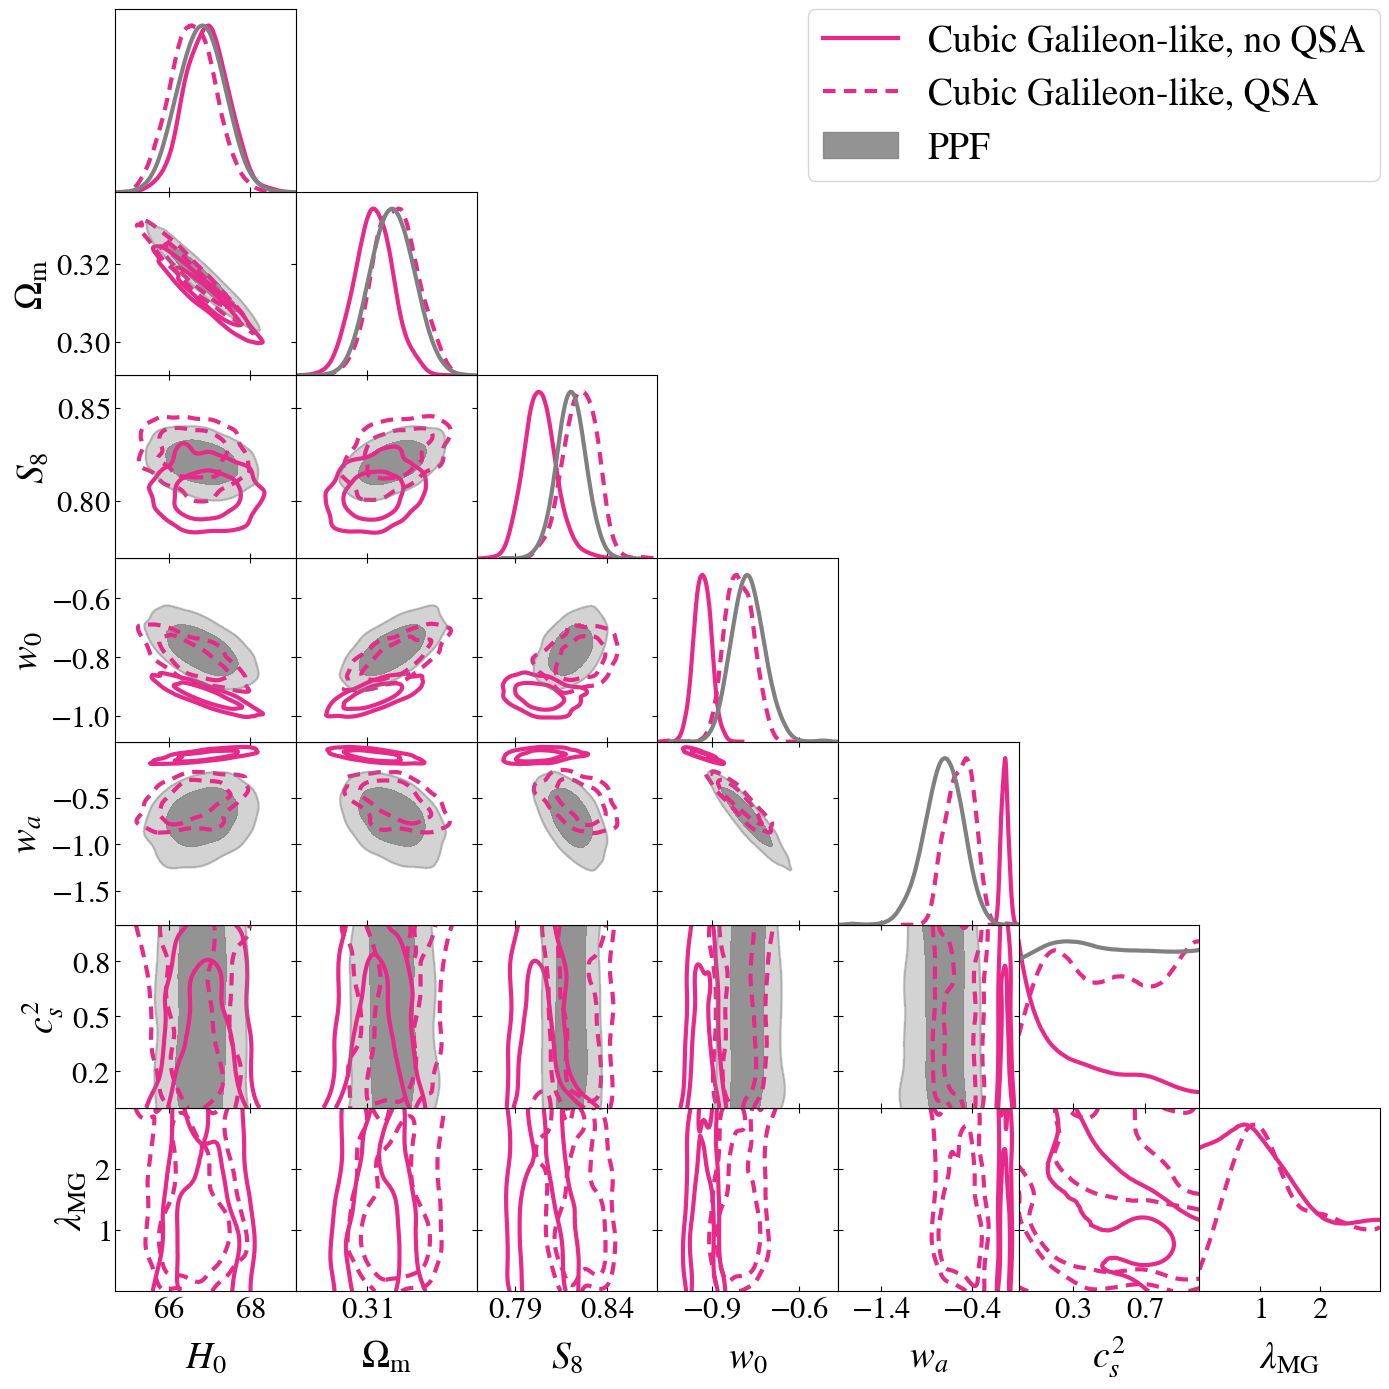

In [8]:
names = ["omega", "kessence", "prop", "cugal"]
noqsa_indices = [117, 118, 119, 120]
qsa_indices = [98, 99, 100, 101]
gr_indices = [76, 84, 76, 76]

for name, label, color, i_noqsa, i_qsa, i_gr in zip(names, labels, utils.colors, noqsa_indices, qsa_indices, gr_indices):
    params = ["H0", "omegam", "S8", "w", "wa", "cs2_0"]
    if chains[i_noqsa].paramNames.hasParam("alpha_K_0"): params.append("alpha_K_0")
    p = plots.get_subplot_plotter()
    p.settings.axes_fontsize=25
    p.settings.axes_labelsize=30
    p.settings.legend_fontsize=30
    p.triangle_plot(
        [chains[i_noqsa], chains[i_qsa], chains[i_gr]],
        params,
        filled=[False, False, True],
        contour_colors=[color, color, "gray"],
        contour_lws=3,
        contour_ls=["-", "--", "-"],
        legend_labels=[f"{label}, no QSA", f"{label}, QSA", "PPF"],
        legend_loc="upper right",
    )
    p.fig.savefig(f"plots/triangle_ds2_subluminal_qsa_vs_noqsa_{name}.pdf", bbox_inches="tight")

In [9]:
# Columns: for each model (Omega_DE, alpha_B, Cubic Galileon, K-essence), QSA then no QSA
columns = []
for i_qsa, i_noqsa in [(98, 117), (100, 119), (101, 120), (99, 118)]:
    columns += [i_qsa, i_noqsa]
print_table(columns, ["omegam", "H0", "S8", "w", "wa", "cs2_0", "alpha_K_0"])

$\Omega_\mathrm{m}$ & $ 0.3164\pm 0.0052$ & $ 0.3077^{+0.0064}_{-0.0044}$ & $ 0.3166\pm 0.0055$ & $ 0.3144^{+0.0049}_{-0.0055}$ & $ 0.3173^{+0.0054}_{-0.0061}$ & $ 0.3117\pm 0.0051$ & $ 0.3118^{+0.0048}_{-0.0056}$ & $ 0.3087^{+0.0077}_{-0.010}$ \\ \hline
$H_0$ & $ 66.67\pm 0.52$ & $ 67.53^{+0.47}_{-0.63}$ & $ 66.63\pm 0.55$ & $ 66.70\pm 0.53$ & $ 66.60\pm 0.56$ & $ 66.93\pm 0.54$ & $ 66.95^{+0.59}_{-0.49}$ & $ 67.24^{+0.96}_{-0.67}$ \\ \hline
$S_8$ & $ 0.8232\pm 0.0089$ & $ 0.8114\pm 0.0077$ & $ 0.8222\pm 0.0087$ & $ 0.8089\pm 0.0076$ & $ 0.826^{+0.010}_{-0.0085}$ & $ 0.8038^{+0.0080}_{-0.0094}$ & $ 0.8031\pm 0.0079$ & $ 0.7986^{+0.0067}_{-0.0099}$ \\ \hline
$w_0$ & $ -0.812\pm 0.048$ & $ -0.917^{+0.027}_{-0.024}$ & $ -0.811^{+0.041}_{-0.047}$ & $ -0.864\pm 0.036$ & $ -0.805\pm 0.050$ & $ -0.932\pm 0.030$ & $ -0.941^{+0.027}_{-0.032}$ & $ -0.946^{+0.021}_{-0.035}$ \\ \hline
$w_a$ & $ -0.51\pm 0.15$ & $ -0.206^{+0.094}_{-0.069}$ & $ -0.50^{+0.15}_{-0.12}$ & $ -0.273^{+0.067}_{-0.098}$ &

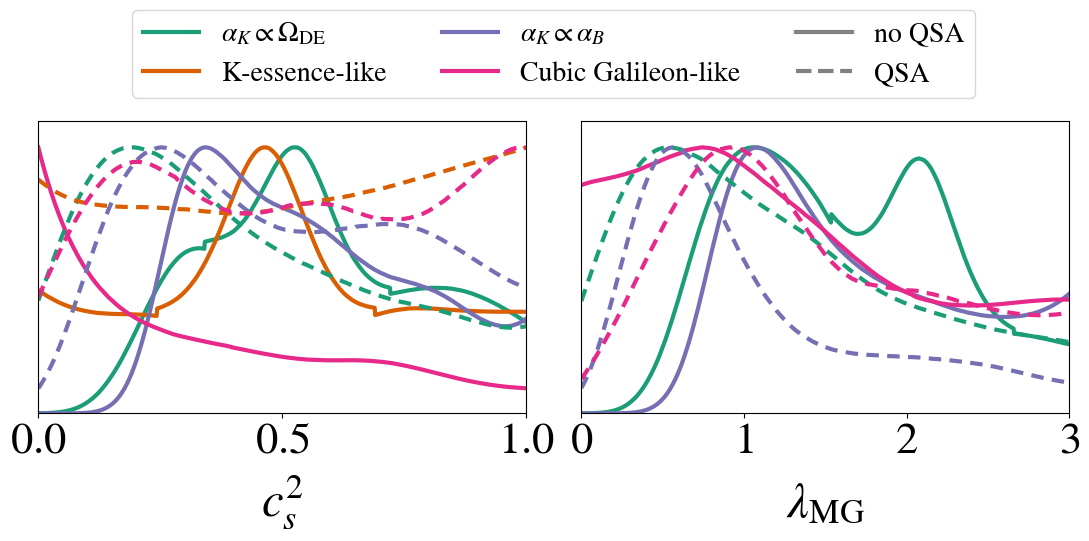

In [10]:
p = plots.get_subplot_plotter(width_inch=11, subplot_size_ratio=4/5)
p.settings.axes_fontsize=32
p.settings.axes_labelsize=35
p.plots_1d(
    [chains[i] for i in noqsa_indices] + [chains[i] for i in qsa_indices],
    ["cs2_0", "alpha_K_0"],
    colors=utils.colors[:4] + utils.colors[:4],
    lws=3,
    ls=["-"]*4 + ["--"]*4,
    nx=2,
    legend_labels=[],
)

handles = [Line2D([], [], linewidth=3, linestyle="-", color=color) for color in utils.colors[:4]]
handles += [Line2D([], [], linewidth=3, linestyle="-", color="gray"), Line2D([], [], linewidth=3, linestyle="--", color="gray")]
p.fig.legend(handles, labels + ["no QSA", "QSA"],
             loc="upper center",
             ncol=3,
             fontsize=20,
             bbox_to_anchor=(0.508, 1.25),
             bbox_transform=p.fig.transFigure,
             frameon=True)

p.fig.savefig("plots/lambda_mg_cs2_subluminal_ds2_qsa_vs_noqsa.pdf", bbox_inches="tight")

In [11]:
for i, chain in chains.items():
    try:
        print(i, chain.getGelmanRubin())
    except ValueError:
        print(i, "n/a (getdist could not compute R-1 after burn-in)")

76 n/a (getdist could not compute R-1 after burn-in)
84 n/a (getdist could not compute R-1 after burn-in)
98 n/a (getdist could not compute R-1 after burn-in)
99 n/a (getdist could not compute R-1 after burn-in)
100 n/a (getdist could not compute R-1 after burn-in)
101 n/a (getdist could not compute R-1 after burn-in)
117 n/a (getdist could not compute R-1 after burn-in)
118 n/a (getdist could not compute R-1 after burn-in)
119 n/a (getdist could not compute R-1 after burn-in)
120 n/a (getdist could not compute R-1 after burn-in)
